# Questão 1 — Double K-means no Spambase (Notebook Unificado)

Este notebook centraliza os **7 experimentos** de pré-processamento da Questão 1 (`revisada`, `binarizacao`, `clip_log_standard`, `filtragem_dominio`, `log_minmax`, `quantile_uniform` e `tratamento_diferenciado_runs`) usando os módulos compartilhados em `questao1/src/`.

- Os notebooks individuais originais permanecem preservados em `questao1/notebooks/`.
- A variável de classe `y_original` **não participa** de nenhuma etapa de pré-processamento ou agrupamento.
- Os rótulos oficiais utilizados na Questão 2 vêm da estratégia **`log_minmax`** ($K^*=3, H^*=3$, `seed=33044`).

In [1]:
from pathlib import Path
import sys

caminho_atual = Path.cwd()
raiz_repo = caminho_atual if (caminho_atual / 'questao1').is_dir() else caminho_atual.parent
if not (raiz_repo / 'questao1').is_dir():
    raise RuntimeError('Execute o notebook a partir da raiz do repositório ou da pasta questao1')
if str(raiz_repo) not in sys.path:
    sys.path.insert(0, str(raiz_repo))

import matplotlib.pyplot as plt
import pandas as pd
from questao1.src.dados import PASTA_RESULTADOS, carregar_spambase
from questao1.src.preprocessamentos import ESTRATEGIAS, listar_estrategias, aplicar_preprocessamento
from questao1.src.experimento import (
    carregar_resumo_comparativo,
    executar_estrategia,
    plotar_graficos,
)
from questao1.src.auditoria import executar_auditoria_baseline

print('Raiz do projeto:', raiz_repo)
print('Estratégias disponíveis:', listar_estrategias())

Raiz do projeto: C:\Users\Felipe Lima\projetos\questao1_revisada
Estratégias disponíveis: ['revisada', 'binarizacao', 'clip_log_standard', 'filtragem_dominio', 'log_minmax', 'quantile_uniform', 'tratamento_diferenciado_runs']


## 1. Configuração do Experimento

Escolha abaixo `ESTRATEGIA` (uma das 7 opções acima, ou `'todas'` para validar/executar todas).
- `REUTILIZAR_GRID_SALVO = True`: reproduz instantaneamente os 9 melhores pares $(K,H)$ pelas `best_seed` salvas em `resultados/<estrategia>/resultados_KH.csv` conferindo $W$.
- `REUTILIZAR_GRID_SALVO = False`: executa novamente os 9 pares × 100 reinicializações válidas.
- `SALVAR_RESULTADOS = False`: mantenha `False` para apenas inspecionar/reproduzir sem sobrescrever os artefatos já salvos.

In [2]:
ESTRATEGIA = 'log_minmax'          # ou 'revisada', 'binarizacao', ..., ou 'todas'
REUTILIZAR_GRID_SALVO = True
SALVAR_RESULTADOS = False
EXECUTAR_AUDITORIA_REVISADA = False
N_RESTARTS = 100
BASE_SEED = 42
MAX_ITER = 200

## 2. Carga dos Dados Brutos e Execução / Reprodução da Grade

In [3]:
X_df, X_original, y_original, feature_names = carregar_spambase()
print(f'Spambase carregado: {X_original.shape[0]} objetos × {X_original.shape[1]} atributos')

alvos = listar_estrategias() if ESTRATEGIA == 'todas' else [ESTRATEGIA]
execucoes = {}
for nome in alvos:
    res = executar_estrategia(
        nome=nome,
        reutilizar_grid_salvo=REUTILIZAR_GRID_SALVO,
        n_restarts=N_RESTARTS,
        base_seed=BASE_SEED,
        max_iter=MAX_ITER,
        salvar=SALVAR_RESULTADOS,
        exibir_graficos=False,
    )
    execucoes[nome] = res
    av = res['avaliacao']
    print(f'[{nome}] (K*, H*)=({av.K_star}, {av.H_star}) | Silhueta={av.silhouette:.6f} | ARI={av.ari:.6f} | W={av.best_solution.objective:.4f}')

Spambase carregado: 4601 objetos × 57 atributos


[log_minmax] (K*, H*)=(3, 3) | Silhueta=0.129219 | ARI=0.391111 | W=2906.2307


## 3. Detalhamento da Estratégia Selecionada

In [4]:
estrategia_foco = alvos[0] if ESTRATEGIA == 'todas' else ESTRATEGIA
res_foco = execucoes[estrategia_foco]
av = res_foco['avaliacao']
cfg = res_foco['config']

print(f'Estratégia em foco: {cfg.titulo}')
display(av.results_df)
display(res_foco['checks_df'])
display(av.metadata_df)

Estratégia em foco: log(1+x) + MinMaxScaler


,K,H,best_objective_W,silhouette,best_seed,n_iterations_best,valid_runs,invalid_attempts,total_attempts
0,2,1,4300.963033,0.125882,21042,12,100,0,100
1,2,2,3127.145726,0.109001,22044,15,100,0,100
2,3,1,4268.587405,0.049616,31042,13,100,0,100
3,3,2,3091.829150,0.064403,32043,20,100,0,100
4,3,3,2906.230738,0.129219,33044,14,100,2,102
5,4,1,4256.956988,0.024264,41042,66,100,0,100
6,4,2,3043.446065,0.066331,42042,19,100,2,102
7,4,3,2829.128803,0.067895,43053,30,100,1,101
8,4,4,2715.636539,0.071414,44044,16,100,11,111


,K,H,object_clusters_found,variable_clusters_found,objective_non_increasing
0,2,1,2,1,True
1,2,2,2,2,True
2,3,1,3,1,True
3,3,2,3,2,True
4,3,3,3,3,True
5,4,1,4,1,True
6,4,2,4,2,True
7,4,3,4,3,True
8,4,4,4,4,True


,K_star,H_star,silhouette,objective_W,best_seed,adjusted_rand_index,n_restarts_per_KH,scaling_used_for_clustering
0,3,3,0.129219,2906.230738,33044,0.391111,100,log1p + MinMaxScaler


Matriz de Protótipos dos Blocos (G):


,var_cluster_0,var_cluster_1,var_cluster_2
obj_cluster_0,0.194479,0.022612,0.025559
obj_cluster_1,0.240859,0.132449,0.024273
obj_cluster_2,0.420265,0.008495,0.090361


Matriz de Contingência (Clusters × Classe a priori):


classe_original,0,1
cluster_double_kmeans,,
0,2218,401
1,265,0
2,305,1412


Distribuição de atributos por cluster de variáveis (H*):


,n_atributos
variable_cluster,
0,4
1,31
2,22


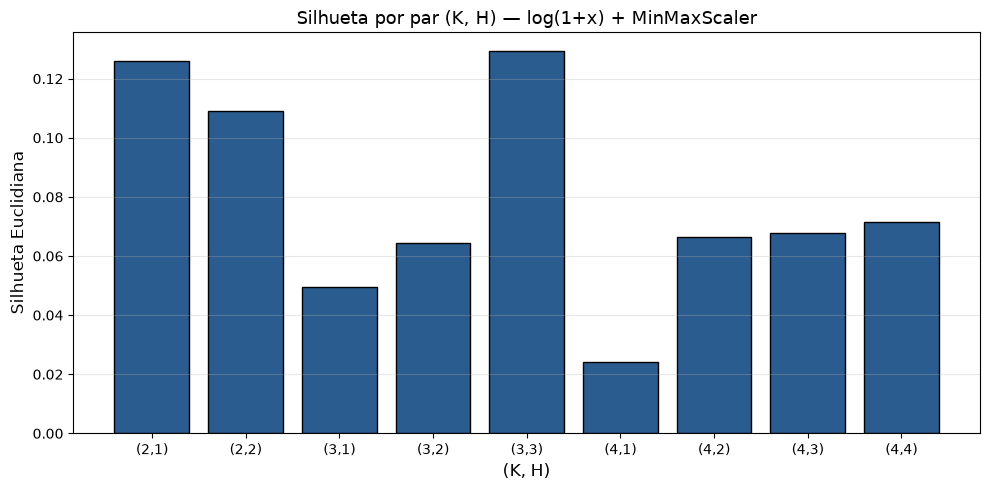

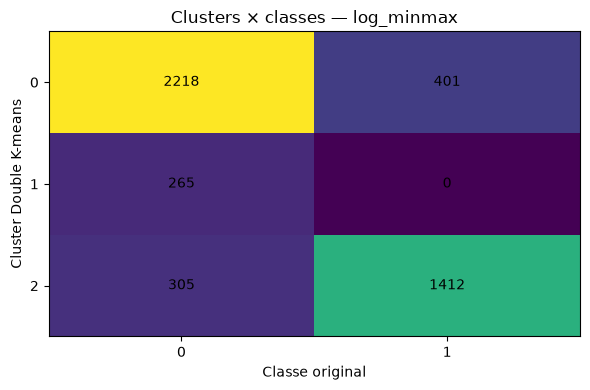

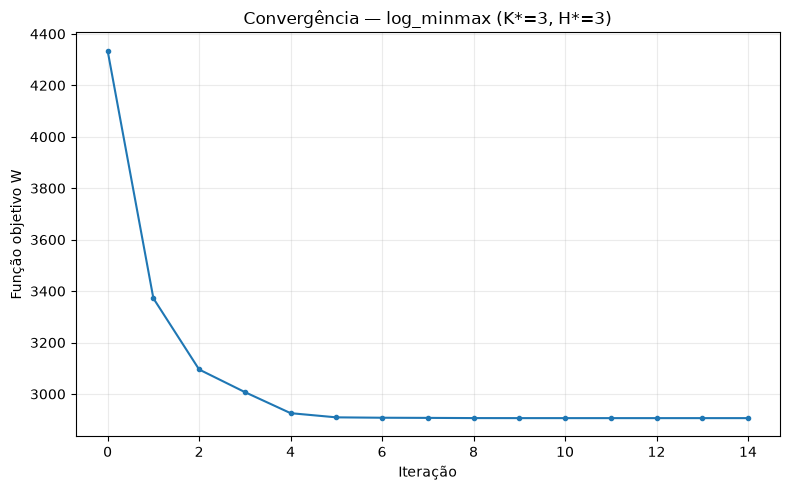

In [5]:
print('Matriz de Protótipos dos Blocos (G):')
display(av.G_df)

print('Matriz de Contingência (Clusters × Classe a priori):')
display(av.contingency)

print('Distribuição de atributos por cluster de variáveis (H*):')
display(av.var_df['variable_cluster'].value_counts().sort_index().to_frame('n_atributos'))

plotar_graficos(av, cfg, output_dir=None, exibir=True)

## 4. Auditoria da Linha de Base (`revisada`, opcional)

In [6]:
if EXECUTAR_AUDITORIA_REVISADA and 'revisada' in execucoes:
    res_rev = execucoes['revisada']
    av_rev = res_rev['avaliacao']
    aud = executar_auditoria_baseline(
        X=res_rev['X'],
        X_df=res_rev['X_df'],
        X_original=res_rev['X_original'],
        y_original=res_rev['y_original'],
        feature_names=res_rev['feature_names'],
        best_runs=res_rev['best_runs'],
        K_star=av_rev.K_star,
        H_star=av_rev.H_star,
        audit_dir=PASTA_RESULTADOS / 'revisada' / 'auditoria',
        salvar=SALVAR_RESULTADOS,
        exibir=True,
    )
    display(aud['ranking_variaveis'].head(15))
else:
    print('Auditoria detalhada desativada (defina EXECUTAR_AUDITORIA_REVISADA=True e inclua "revisada" para exibir).')

Auditoria detalhada desativada (defina EXECUTAR_AUDITORIA_REVISADA=True e inclua "revisada" para exibir).


## 5. Comparativo Consolidado das 7 Estratégias

,estrategia,titulo,K_star,H_star,silhouette,objective_W,best_seed,ARI,tamanhos_clusters,arquivo_q2
0,revisada,Original / Revisada (StandardScaler puro),2,2,0.659631,244486.698350,22042,-0.004950,34 / 4567,spambase_com_clusters.csv
1,binarizacao,Binarização (x > 0) + log1p(maiúsculas) + Stan...,3,3,0.210019,208777.145868,33337,0.269498,1344 / 3025 / 232,spambase_com_clusters_binarizado.csv
2,clip_log_standard,Clip 99% + log(1+x) + StandardScaler,2,1,0.172059,251544.659599,21042,0.129196,1372 / 3229,spambase_com_clusters_clip_log_standard.csv
3,filtragem_dominio,Filtragem de Termos de Domínio (49 atributos) ...,2,1,0.292614,220269.239794,21042,0.136301,1129 / 3472,spambase_com_clusters_filtragem_dominio.csv
4,log_minmax,log(1+x) + MinMaxScaler,3,3,0.129219,2906.230738,33044,0.391111,2619 / 265 / 1717,spambase_com_clusters_log_minmax.csv
5,quantile_uniform,QuantileTransformer (uniforme),3,3,0.190317,21926.532340,33087,0.292525,2787 / 1240 / 574,spambase_com_clusters_quantile_uniform.csv
6,tratamento_diferenciado_runs,Tratamento Diferenciado de Maiúsculas por Bloco,2,2,0.653702,244484.996416,22116,-0.004950,4567 / 34,spambase_com_clusters_runs_diferenciado.csv


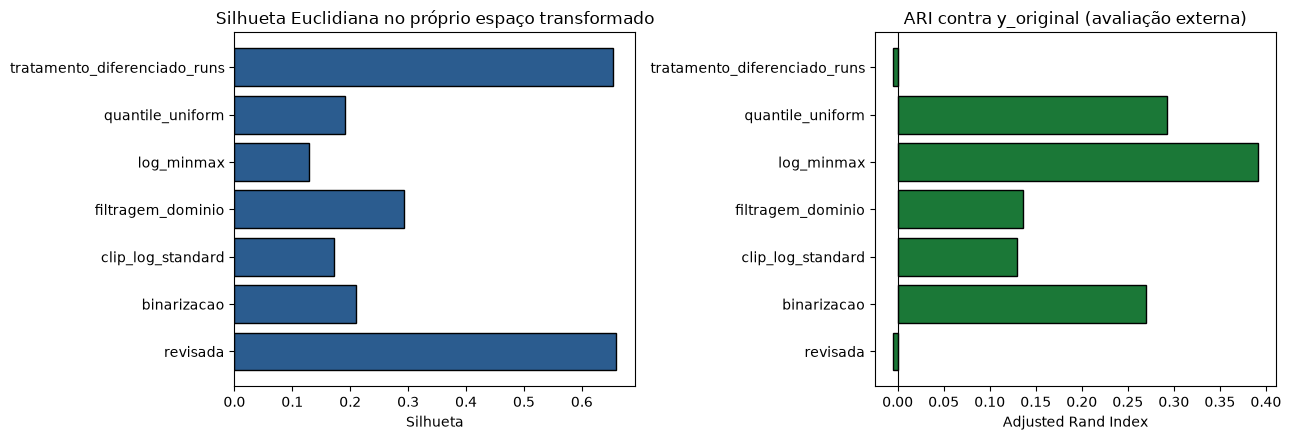

In [7]:
resumo_df = carregar_resumo_comparativo()
display(resumo_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(resumo_df['estrategia'], resumo_df['silhouette'], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Silhueta Euclidiana no próprio espaço transformado')
axes[0].set_xlabel('Silhueta')

axes[1].barh(resumo_df['estrategia'], resumo_df['ARI'], color='#1b7837', edgecolor='black')
axes[1].set_title('ARI contra y_original (avaliação externa)')
axes[1].set_xlabel('Adjusted Rand Index')
axes[1].axvline(0, color='black', linewidth=0.8)

fig.tight_layout()
plt.show()